First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \


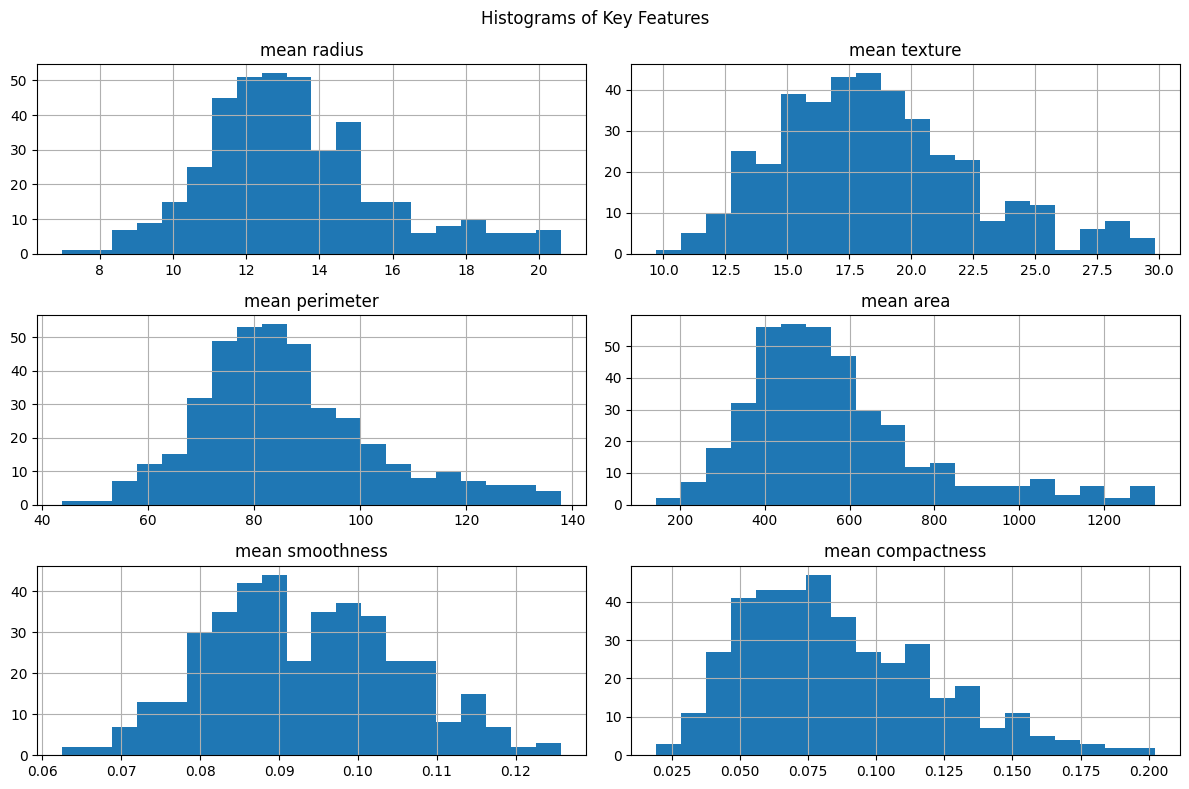

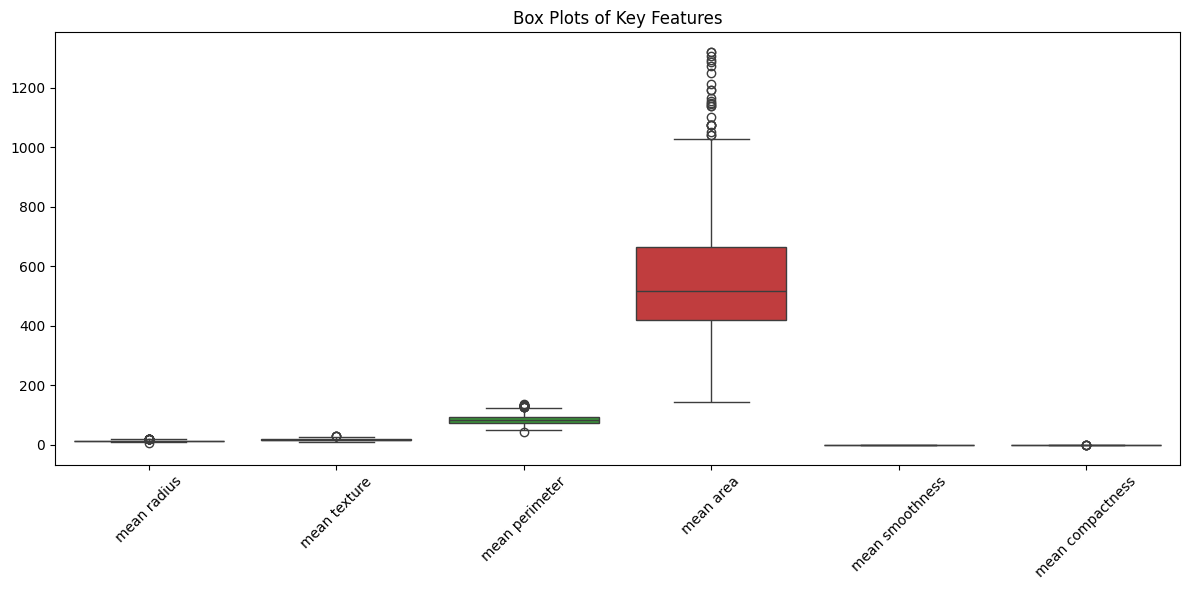

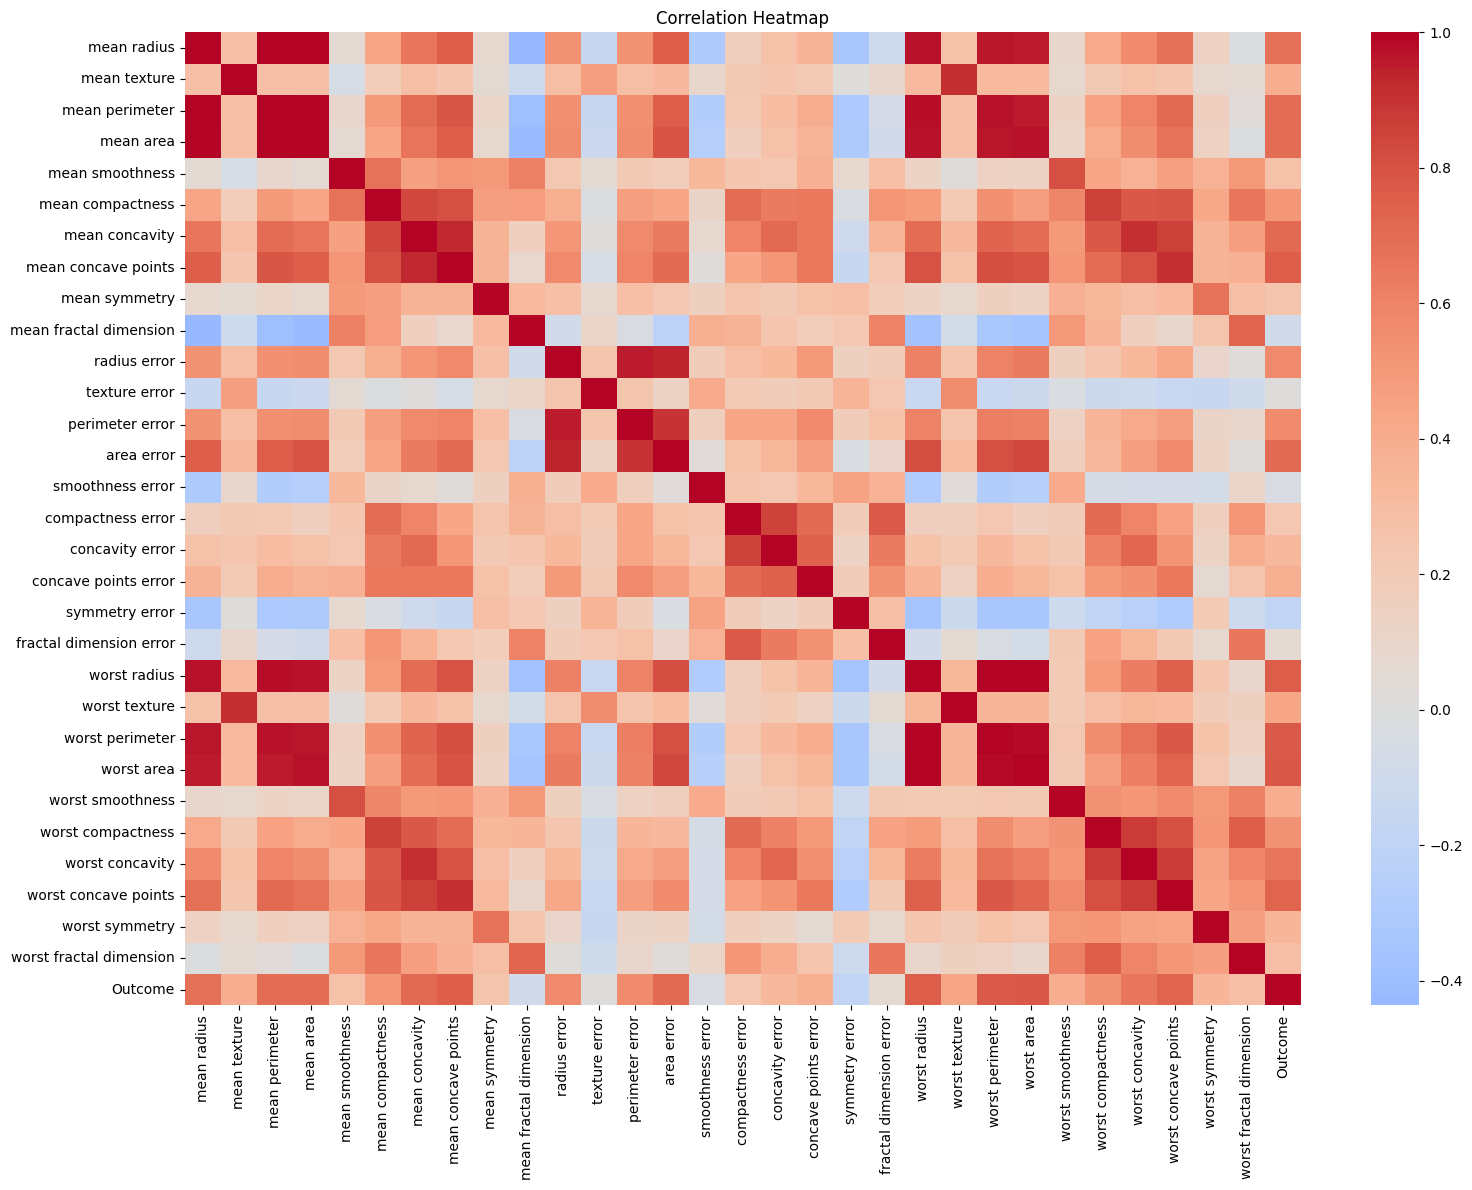

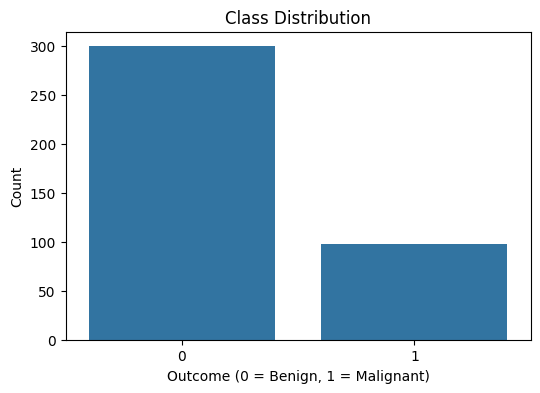


Class Distribution:
Outcome
0    300
1     98
Name: count, dtype: int64

Class Distribution Percentage:
Outcome
0    75.376884
1    24.623116
Name: proportion, dtype: float64

Training set: (318, 30)
Testing set: (80, 30)

================ MODEL EVALUATION ================

Accuracy:
0.9625

Precision:
Class 0 (Benign): 0.9672131147540983
Class 1 (Malignant): 0.9473684210526315

Recall:
Class 0 (Benign): 0.9833333333333333
Class 1 (Malignant): 0.9

F1-Score:
Class 0 (Benign): 0.9752066115702479
Class 1 (Malignant): 0.9230769230769231

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.98      0.98        60
   Malignant       0.95      0.90      0.92        20

    accuracy                           0.96        80
   macro avg       0.96      0.94      0.95        80
weighted avg       0.96      0.96      0.96        80


Confusion Matrix:
[[59  1]
 [ 2 18]]


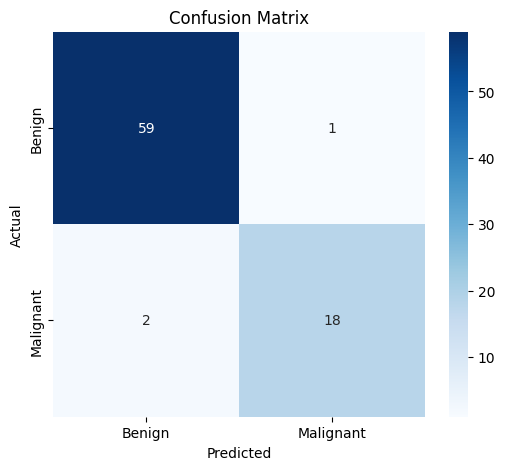


AUC Score:
0.9916666666666667


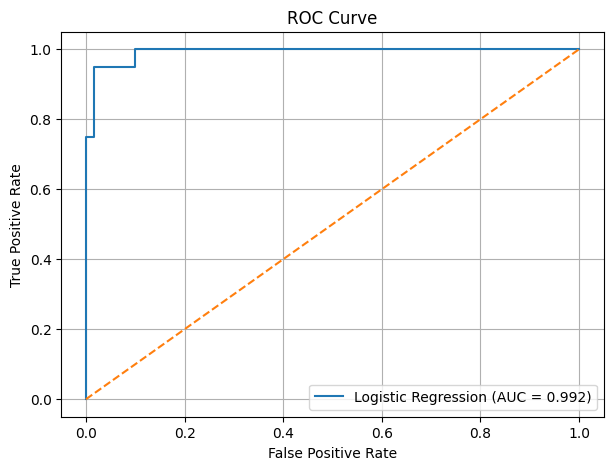

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# 1: DATA ACQUISITION AND EXPLORATION

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

df["Outcome"] = (data.target == 0).astype(int)

print("First 5 rows:")
print(df.head())

print("\nShape:")
print(df.shape)

# Summary statistics
print("\nSummary Statistics:")
print(df.describe())

print("\nMedian:")
print(df.median())

print("\nStandard Deviation:")
print(df.std())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

df = df.drop_duplicates()

numerical_features = df.drop(columns=["Outcome"]).columns

Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)
IQR = Q3 - Q1

outliers = ((df[numerical_features] < (Q1 - 1.5 * IQR)) |
            (df[numerical_features] > (Q3 + 1.5 * IQR))).sum()

print("\nOutliers in each feature:")
print(outliers)

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[~((df[numerical_features] < lower) |
          (df[numerical_features] > upper)).any(axis=1)]

print("\nShape after removing duplicates and outliers:")
print(df.shape)

# VISUALIZATION

df[numerical_features[:6]].hist(figsize=(12, 8), bins=20)
plt.suptitle("Histograms of Key Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numerical_features[:6]])
plt.xticks(rotation=45)
plt.title("Box Plots of Key Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x="Outcome", data=df)
plt.title("Class Distribution")
plt.xlabel("Outcome (0 = Benign, 1 = Malignant)")
plt.ylabel("Count")
plt.show()

print("\nClass Distribution:")
print(df["Outcome"].value_counts())

print("\nClass Distribution Percentage:")
print(df["Outcome"].value_counts(normalize=True) * 100)

# 2: DATA PREPROCESSING

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3: LOGISTIC REGRESSION

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

# EVALUATION

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average=None)
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)

print("\n================ MODEL EVALUATION ================")

print("\nAccuracy:")
print(accuracy)

print("\nPrecision:")
print("Class 0 (Benign):", precision[0])
print("Class 1 (Malignant):", precision[1])

print("\nRecall:")
print("Class 0 (Benign):", recall[0])
print("Class 1 (Malignant):", recall[1])

print("\nF1-Score:")
print("Class 0 (Benign):", f1[0])
print("Class 1 (Malignant):", f1[1])

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

# CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ROC CURVE AND AUC

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

print("\nAUC Score:")
print(auc_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

This code uses the Breast Cancer Wisconsin dataset to build a logistic regression model to classify tumors as benign or malignant. It explores the data by calculating summary statistics, checking missing values and duplicates, identifying outliers, and creating histograms, box plots, a correlation heatmap, and a class distribution plot. The data is split into training and testing sets using stratified sampling, and the features are standardized. The model is then trained and evaluated using accuracy, precision, recall, F1-score, a confusion matrix, and the ROC curve with AUC score.

